# EDA: Hospital Counts by Provider Type

Question from the team: keep all hospital types, or focus on short-term acute + critical access hospitals (CAH)?

Data: `cost_report_clean` table built by `src/pipeline.py` (CMS Hospital Provider Cost Reports, 2015–2022).

## 1. Load data

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

conn = sqlite3.connect("../data/hospital_cost_reports.db")
df = pd.read_sql("""
    SELECT file_year, provider_ccn, provider_type, ccn_facility_type,
           type_of_control, rural_versus_urban, number_of_beds,
           net_income, total_assets, cash_on_hand_and_in_banks
    FROM cost_report_clean
""", conn)

print(df.shape)  # expect (48353, 10)

(48353, 10)


## 2. What codes are in the type fields?

CMS provider type codes (verify against the data dictionary): 1 = general short-term, 2 = general long-term, 3 = cancer, 4 = psychiatric, 5 = rehab, 6 = religious non-medical, 7 = children's, 8 = alcohol/drug, 9 = other.

In [2]:
df[["provider_type", "ccn_facility_type"]].value_counts().sort_index()

provider_type  ccn_facility_type
1              CAH                  10407
               CH                      40
               LTCH                     2
               ORD                     69
               PH                      32
               RH                       1
               RNMHC                    1
               STH                  26279
2              CH                       9
               LTCH                  3007
               PH                       6
               RNMHC                    1
               STH                      6
3              CH                       5
               LTCH                     1
               PH                       1
               RH                       1
               STH                     88
4              CH                       7
               PH                    4694
               RNMHC                    1
               STH                      4
5              CH                      15
 

## 3. Counts by facility type

In [3]:
by_type = (df.groupby("ccn_facility_type")
             .agg(hospital_years=("provider_ccn", "size"),
                  hospitals=("provider_ccn", "nunique"),
                  median_beds=("number_of_beds", "median"))
             .assign(pct_of_rows=lambda t: (100 * t.hospital_years / len(df)).round(1))
             .sort_values("hospital_years", ascending=False))
by_type

,hospital_years,hospitals,median_beds,pct_of_rows
ccn_facility_type,,,,
STH,26397,3559,133.0,54.6
CAH,10807,1395,25.0,22.4
PH,4791,698,84.0,9.9
LTCH,3025,446,47.0,6.3
RH,2389,368,56.0,4.9
CH,765,103,253.0,1.6
RNMHC,110,16,13.0,0.2
ORD,69,9,22.0,0.1


## 4. Do the two type fields agree?

In [4]:
pd.crosstab(df.ccn_facility_type, df.provider_type, margins=True)

provider_type,1,2,3,4,5,6,7,8,9,10,11,All
ccn_facility_type,,,,,,,,,,,,
CAH,10407,0,0,0,0,0,0,1,396,1,2,10807
CH,40,9,5,7,15,0,668,0,21,0,0,765
LTCH,2,3007,1,0,5,0,0,0,5,5,0,3025
ORD,69,0,0,0,0,0,0,0,0,0,0,69
PH,32,6,1,4694,13,0,13,0,32,0,0,4791
RH,1,0,1,0,2384,0,2,0,1,0,0,2389
RNMHC,1,1,0,1,1,105,0,0,1,0,0,110
STH,26279,6,88,4,3,0,0,0,16,0,1,26397
All,36831,3029,96,4706,2421,105,683,1,472,6,3,48353


## 5. Are counts stable across years?

In [5]:
pd.crosstab(df.ccn_facility_type, df.file_year)

file_year,2015,2016,2017,2018,2019,2020,2021,2022
ccn_facility_type,,,,,,,,
CAH,1339,1342,1343,1353,1355,1355,1357,1363
CH,97,99,99,97,95,94,91,93
LTCH,430,417,405,379,362,347,343,342
ORD,9,9,9,9,9,8,8,8
PH,563,575,580,595,610,615,623,630
RH,260,275,278,289,302,314,328,343
RNMHC,16,16,16,14,13,13,12,10
STH,3411,3374,3347,3313,3271,3244,3222,3215


## 6. Hospitals that changed type during the panel

Important for next-year prediction: a switch to CAH changes reimbursement and can look like a distress signal.

In [6]:
changers = df.groupby("provider_ccn")["ccn_facility_type"].nunique()
n_changers = (changers > 1).sum()
print("Hospitals with more than one facility type:", n_changers)

(df[df.provider_ccn.isin(changers[changers > 1].index)]
   .sort_values(["provider_ccn", "file_year"])
   [["provider_ccn", "file_year", "ccn_facility_type", "provider_type"]]
   .head(30))

Hospitals with more than one facility type: 0


,provider_ccn,file_year,ccn_facility_type,provider_type


## 7. What the proposed filter keeps

**Edit `KEEP`** to match the acute and CAH labels you saw in section 3.

In [7]:
KEEP = ["STH", "CAH"]   # <-- edit to match actual labels

missing_labels = [k for k in KEEP if k not in df.ccn_facility_type.unique()]
if missing_labels:
    print("WARNING: these labels are not in the data:", missing_labels)
    print("Available labels:", sorted(df.ccn_facility_type.dropna().unique()))

kept = df[df.ccn_facility_type.isin(KEEP)]
dropped = df[~df.ccn_facility_type.isin(KEEP)]

print(f"Kept:    {len(kept):,} hospital-years ({100*len(kept)/len(df):.1f}%), "
      f"{kept.provider_ccn.nunique():,} hospitals")
print(f"Dropped: {len(dropped):,} hospital-years, {dropped.provider_ccn.nunique():,} hospitals")

Kept:    37,204 hospital-years (76.9%), 4,954 hospitals
Dropped: 11,149 hospital-years, 1,640 hospitals


In [8]:
key = ["net_income", "total_assets", "cash_on_hand_and_in_banks"]
pd.DataFrame({
    "kept_pct_missing": kept[key].isna().mean().mul(100).round(1),
    "dropped_pct_missing": dropped[key].isna().mean().mul(100).round(1),
})

,kept_pct_missing,dropped_pct_missing
net_income,0.3,5.3
total_assets,2.4,12.3
cash_on_hand_and_in_banks,3.7,23.9


## 8. Chart for the Data Summary

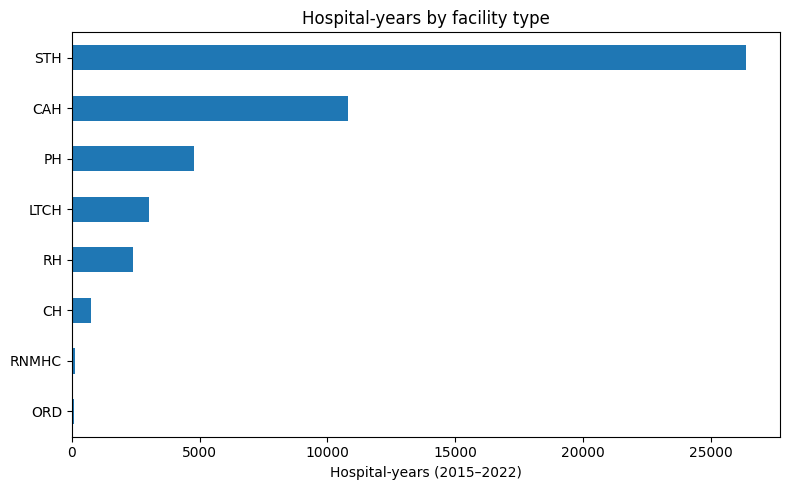

In [9]:
ax = by_type["hospital_years"].sort_values().plot.barh(figsize=(8, 5))
ax.set_xlabel("Hospital-years (2015–2022)")
ax.set_ylabel("")
ax.set_title("Hospital-years by facility type")
plt.tight_layout()
plt.savefig("../reports/hospital_years_by_type.png", dpi=150)
plt.show()

## 9. Summary for Slack

In [10]:
print(f"Total: {len(df):,} hospital-years, {df.provider_ccn.nunique():,} hospitals\n")
for label, row in by_type.iterrows():
    print(f"- {label}: {int(row.hospital_years):,} hospital-years ({row.pct_of_rows}%), {int(row.hospitals):,} hospitals")
print(f"\nHospitals that changed type: {n_changers}")
print(f"Keeping {KEEP}: {len(kept):,} hospital-years ({100*len(kept)/len(df):.1f}%), "
      f"{kept.provider_ccn.nunique():,} hospitals")

Total: 48,353 hospital-years, 6,594 hospitals

- STH: 26,397 hospital-years (54.6%), 3,559 hospitals
- CAH: 10,807 hospital-years (22.4%), 1,395 hospitals
- PH: 4,791 hospital-years (9.9%), 698 hospitals
- LTCH: 3,025 hospital-years (6.3%), 446 hospitals
- RH: 2,389 hospital-years (4.9%), 368 hospitals
- CH: 765 hospital-years (1.6%), 103 hospitals
- RNMHC: 110 hospital-years (0.2%), 16 hospitals
- ORD: 69 hospital-years (0.1%), 9 hospitals

Hospitals that changed type: 0
Keeping ['STH', 'CAH']: 37,204 hospital-years (76.9%), 4,954 hospitals
